# Trabajo Práctico  - Calibración y Pose de la Cámara

## Resolución

## GRUPO: NOMBRE DEL GRUPO

# Integrantes
* integrante
* integrante

### Ejercicio 1 - DLT ecuaciones formales

Siendo $Q\in \mathbb{R}^{2n\times 12}$, ¿qué rango debe tener para asegurar una solución no nula única a menos de un factor de escala? ¿Cuántos puntos, como mínimo, aseguran la solución y qué condición deben cumplir?

Encontrar el vector $\mathbf{m}$ que resuelve la minimización de la ecuación 6.

***
Cada correspondencia entre un punto **real** del mundo $P_i = (U_i, V_i, W_i)$
y su proyección **en píxeles** de la imagen $(u_i, v_i)$ produce las 2 filas
$Q_{2i-1}, Q_{2i} \in \mathbb{R}^{2 \times 12}$ (filas 1 y 2 de la ecuación 6, ver más abajo).

Para $n$ puntos $Q$ es de $2n \times 12$ y se buscan las soluciones que satisfacen
$Q\mathbf{m} = \mathbf{0}$ (ecuación 6), es decir el sistema homogéneo.

Por el teorema del rango y la nulidad se tiene:

$$\operatorname{Rng}(Q) + \dim \operatorname{Nu}(Q) = \#\text{columnas} = 12$$

Si el sistema tuviera solución única, esa sería la trivial $\mathbf{m} = \mathbf{0}$
($\operatorname{Nu}(Q)$ $= \{\mathbf{0}\}$), que físicamente no sirve. Lo que buscamos es **unicidad de dirección**: que todas las soluciones
$\mathbf{m} \neq \mathbf{0}$ sean de la forma $c\,\mathbf{m}_1$, con $\mathbf{m}_1$
fijo — es decir, que no difieran más que en un factor de escala. El conjunto
solución debe ser una recta por el origen:

$$\dim(\operatorname{Nu}(Q)) = 1
\;\qquad\Longrightarrow\qquad \operatorname{Rng}(Q) = 12 - 1 = \boxed{11}$$

***

El rango de $Q$ está acotado por el menor entre su cantidad de filas y columnas:

$$\operatorname{Rng}(Q) \leq \min(2n,\,12)$$

Como probamos que $\operatorname{Rng}(Q) = 11$, se necesita

$$11 \leq \min(2n,\,12) \;\Longleftrightarrow\; 2n \geq 11 \;\Longleftrightarrow\; n \geq 5{,}5$$

Como $n$ debe ser entero, $2n \geq 12$, es decir:

$$n_{\min} = \boxed{6 \text{ puntos}}$$

Los puntos deben cubrir un espacio 3D en posición general: **no pueden ser coplanares entre
sí**. Si todos los puntos estuvieran en un plano, las filas de $Q$ serían redundantes entre sí
(las coordenadas dejarían de aportar información de la tercera dimensión), produciendo columnas
linealmente dependientes, reduciendo el rango de $Q$ y perdiendo la unicidad de la solución.
Es exactamente el caso degenerado del DLT 3D que motiva el método de Zhang para datos coplanares.

***
#### Encontrar el vector $\mathbf{m}$ tal que $\lVert Q\mathbf{m} \rVert$ sea mínimo (ec. 8)

Se busca el vector $\hat{\mathbf{m}}$ que resuelve

$$\min_{\lVert \mathbf{m} \rVert = 1} \; \lVert Q\mathbf{m} \rVert^2$$

Como la norma al cuadrado es un producto interno:

$$\lVert Q\mathbf{m} \rVert^2 = \mathbf{m}^\top\, (Q^\top Q)\, \mathbf{m}$$

Sea la descomposición en valores singulares $Q = U S V^\top$, con $S$ rectangular
($2n \times 12$) y valores singulares $\sigma_1 \geq \sigma_2 \geq \cdots \geq \sigma_{12} \geq 0$.

> **Nota:** $S^2$ **no está definida** porque $S$ es rectangular; en su lugar trabajamos con
> $\hat{S} = S^\top S$, que sí es cuadrada ($12 \times 12$) y diagonal. En $S$ los $\sigma_i$
> están en las primeras 12 posiciones de la diagonal; al hacer $S^\top S$ sobreviven solo los
> $\sigma_i^2$ en la diagonal.

$$\hat{S} \;=\; S^\top S \;=\; \operatorname{diag}(\sigma_1^2, \ldots, \sigma_{12}^2) \;\in\; \mathbb{R}^{12 \times 12}$$

Entonces $Q^\top Q$ se diagonaliza ortogonalmente (usando que $U$ es ortogonal, $U^\top U = I$):

$$Q^\top Q \;=\; (U S V^\top)^\top (U S V^\top)
\;=\; V S^\top \, U^\top U \, S V^\top
\;=\; V \, S^\top S \, V^\top
\;=\; V \, \hat{S} \, V^\top$$

Con $\mathbf{y} = V^\top \mathbf{m}$ y usando que $V$ ortogonal no cambia la norma
($\lVert \mathbf{y} \rVert = \lVert \mathbf{m} \rVert = 1$):

$$\mathbf{m}^\top V \hat{S} V^\top \mathbf{m}
\;=\; \mathbf{y}^\top \hat{S} \mathbf{y}
\;=\; \sum_{i=1}^{12} \sigma_i^2 \, y_i^2$$

$$\min_{\lVert \mathbf{m} \rVert = 1} \lVert Q\mathbf{m} \rVert^2
\;=\; \min_{\lVert \mathbf{y} \rVert = 1} \mathbf{y}^\top \hat{S} \mathbf{y}
\;=\; \min_{\lVert \mathbf{y} \rVert = 1} \sum_{i=1}^{12} \sigma_i^2 y_i^2$$

Como cada $\sigma_i^2 \geq \sigma_{12}^2$, pues están ordenados por la descomposición SVD, se tiene que:

$$\sum_{i=1}^{12} \sigma_i^2 y_i^2 \;\geq\; \sigma_{12}^2 \sum_{i=1}^{12} y_i^2 \;=\; \sigma_{12}^2$$

y la cota se alcanza eligiendo $y_i = 0$ para $i \neq 12$ y $y_{12} = 1$, es decir
$\mathbf{y} = \mathbf{e}_{12}$ (toda la masa de la restricción concentrada en el menor
valor singular).

#### Resultado

Volviendo a la variable original:

$$\min_{\lVert \mathbf{m} \rVert = 1} \lVert Q\mathbf{m} \rVert^2 = \sigma_{12}^2
\qquad\Longrightarrow\qquad \hat{\mathbf{m}} = V\,\mathbf{e}_{12} \;=\; \mathbf{v}_{12}$$

$$\boxed{\hat{\mathbf{m}} = \pm\, \mathbf{v}_{12} \quad \text{con} \quad
\lVert Q\hat{\mathbf{m}} \rVert_{\min} = \sigma_{12}}$$

es decir, el autovector **derecho** asociado al menor valor singular de $Q$
(autovalor $\sigma_{12}^2$ de $Q^\top Q$: la última **columna** de $V$). El signo es
arbitrario porque el sistema es homogéneo: $\pm\mathbf{v}_{12}$ definen la misma recta
solución.

**Interpretación.** Con $n = 6$ puntos exactos y en posición general, $\sigma_{12} = 0$
($\dim \operatorname{Nu}(Q) = 1$) y $\mathbf{v}_{12}$ es el vector nulo del sistema: la
solución exacta del DLT. Con datos reales (ruido), $\sigma_{12} > 0$ y $\mathbf{v}_{12}$ es
la mejor aproximación al núcleo en mínimos cuadrados homogéneos. Es lo que implementa
`resolverDLT3D` tomando la última fila de $V^\top$.

### Ejercicio 2 - Calibración con puntos 3D

a) Utilizando los datos de la carpeta $\texttt{calib/3d}$ calcular $\mathbf{R}$,  $\mathbf{t}$ y $\mathbf{K}$.

Calcular un nuevo set de parámetros para 

b) $\alpha_u = \alpha_v$ 

c) $K_{12}=0$



### Ejercicio 3 - Calibración con puntos coplanares

> ¿Qué rango debe tener $Q \in \mathbb{R}^{2n\times 9}$ para asegurar
> una solución única de $H$ a menos de un factor de escala?

**Demostración:**

Por la ecuación (11) del TP: $Q\mathbf{h} = \mathbf{0}$, con $Q$ de $2n \times 9$
y $\mathbf{h} = \vec{H}$ vectorizado de $9 \times 1$, donde $H$ es una homografía
válida de rango 3.

Por como está construido $\mathbf{h}$, es un vector no nulo
que pertenece al núcleo de $Q$, es decir $\mathbf{h} \in \mathcal{N}(Q)$ y
$\mathbf{h} \neq \mathbf{0}$.

Por lo tanto $\mathbf{h}$ es una solución no trivial del espacio nulo de $Q$.

Para que $\mathbf{h}$ sea una solución única a menos de un factor de escala, el conjunto de soluciones de $Q\mathbf{h}=0$ debe ser una recta que pasa por el origen: $\{c\,\mathbf{h}: c \in \mathbb{R}, c\neq 0\}$, es decir, $\dim\mathcal{N}(Q)=1$.

Por el teorema del rango y la nulidad, $\operatorname{rango}(Q) + \dim \mathcal{N}(Q) = 9$ 
($Q$ tiene 9 columnas). Dado que $\dim \mathcal{N}(Q) = 1$, entonces $$\operatorname{rango}(Q) = 9 - 1 = \boxed{8}$$

Como $\operatorname{rango}(Q) \le \min(2n,\,9)$, para alcanzar rango 8 se necesita
$2n \geq 8$, es decir, **al menos $n = 4$ puntos** por vista, y basta que exista un grupo de 4 en posición general (ninguna terna de esos 4 colineal). El tablero de 77 esquinas lo cumple de sobra.

Resolver la calibración para el caso de puntos coplanares, trabajando sobre los datos de la carpeta $\texttt{calib/coplanar}$ con las imágenes $\texttt{Im\_R\_1.png}$ a $\texttt{Im\_R\_20.png}$.


In [1]:
import os
import importlib
import numpy as np
import alc

importlib.reload(alc)
np.set_printoptions(precision=4, suppress=True)

# rutas (notebook en la raíz del repo)
PATH_CORNERS = os.path.join("calib", "coplanar", "detected_corners.txt")
N_IMG, N_PTS = 20, 77

In [2]:
# proyecciones detectadas: 1 fila por imagen, esquinas intercaladas (u,v)
detected = np.loadtxt(PATH_CORNERS)              # (20, 154)
print("detected:", detected.shape)               # chequeo del formato

# puntos del tablero: analíticos, fila-mayor (X=30i, Y=30j, Z=0) en mm
n = np.arange(N_PTS)
objPts = np.zeros((N_PTS, 3))
objPts[:, 0] = 30.0 * (n % 11)
objPts[:, 1] = 30.0 * (n // 11)
objPts[:, 2] = 0.0   # plano W=0 del tablero
print("objPts[0], objPts[11], objPts[76]:", objPts[0], objPts[11], objPts[76])

X, Y = objPts[:, 0], objPts[:, 1]        # usadas por el QA de reproyección y los plots

detected: (20, 154)
objPts[0], objPts[11], objPts[76]: [0. 0. 0.] [ 0. 30.  0.] [300. 180.   0.]


### Calibración (Zhang 2000, caso coplanar)

Cada imagen aporta la homografía $H_j$ (solución de mínimos cuadrados
homogéneos, ec. 8) y las restricciones

$$ \mathbf{c}_1^{j\top} B\, \mathbf{c}_2^j = 0, \qquad
   \mathbf{c}_1^{j\top} B\, \mathbf{c}_1^j \;=\; \mathbf{c}_2^{j\top} B\, \mathbf{c}_2^j $$

con $B = K^{-\top}K^{-1}$ simétrica ⇒ 6 incógnitas $\mathbf b=(B_{11},B_{12},B_{22},B_{13},B_{23},B_{33})^\top$.
Armando $A\in\mathbb{R}^{2N\times 6}$ y tomando el **vector nulo** de $A$ (norma 1)
obtenemos $\mathbf b$; el signo se elige de modo que $B$ sea definida positiva,
y $K = (L^\top)^{-1}$ con $B = LL^\top$ (Cholesky), normalizada con $K_{33}=1$.

>b) Obtener la matriz $\mathbf{K}$

In [3]:
# 1. Homografía por imagen: DLT coplanar (ec. 11 + ec. 8)
Hlst = []
for k in range(N_IMG):
    imgPts = detected[k].reshape(N_PTS, 2)
    Q  = alc.obtenerQ2d(imgPts, objPts)            # (154, 9)
    H  = alc.resolverDLT2D(Q)                      # (3, 3), ‖h‖=1
    Hlst.append(H)

# 2. Matriz A de restricciones de Zhang (ec. 13): 2 filas por vista
A = alc.armarA(Hlst)                               # (40, 6)  (2 filas por vista)

# 3. K: núcleo de A → b → B def. positiva → Cholesky → K (K33=1)
K = alc.calcularMatrizK2D(A)
print("K:\n", K)

K:
 [[744.4807  -0.9115 519.5372]
 [  0.     755.6784 298.5621]
 [  0.       0.       1.    ]]


error de reproyección máximo por vista (px):
[0.3687 0.4036 0.4655 0.3998 0.3757 0.4352 0.4065 0.4186 0.3927 0.545
 0.3803 0.4096 0.4428 0.4493 0.6029 0.4586 0.4193 0.5645 0.466  0.412 ]
máximo global: 0.603 px | promedio: 0.441 px


Text(0.5, 1.0, 'Im_R_1: esquinas detectadas vs reproyectadas')

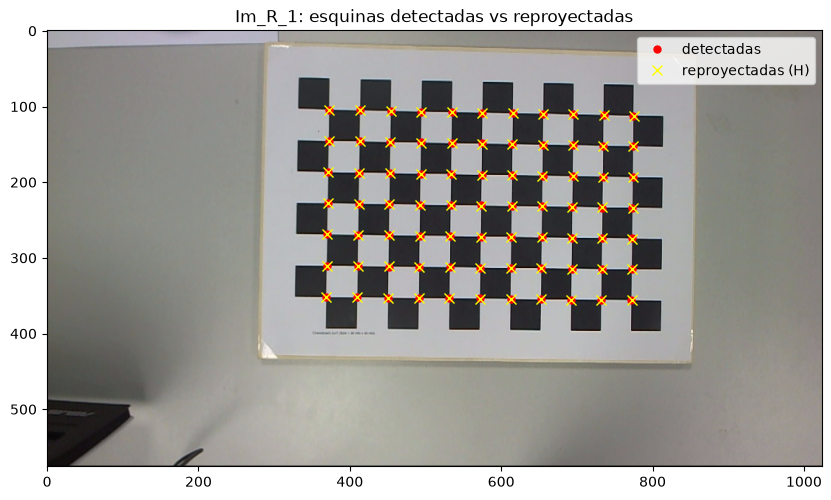

In [4]:
# ------------------------------------------------------------------
# QA de reproyección (todas las vistas) + visual de Im_R_1
# ------------------------------------------------------------------
# La homografía proyecta la esquina del tablero (X, Y, 1)ᵀ al plano de
# la imagen: u = (H·p)₀/(H·p)₂, v = (H·p)₁/(H·p)₂.
# Si la calibración es correcta, las 77 esquinas reproyectadas deben
# caer sobre las detectadas, con diferencia ~ ruido de detección (~0.5 px).

# 1) Error máximo por vista: (proj - medido) en px con la H de cada vista
errs = np.zeros(N_IMG)
for k in range(N_IMG):
    imgPts = detected[k].reshape(N_PTS, 2)
    p_hom = np.vstack([X, Y, np.ones(N_PTS)])          # esquinas homogéneas (3, 77)
    w = np.zeros((3, N_PTS))
    for p in range(N_PTS):
        w[:, p] = alc.multiplicar(Hlst[k], p_hom[:, p])   # H·p
    proj = np.vstack([w[0] / w[2], w[1] / w[2]]).T      # reproyección (77, 2)
    e2 = (proj[:, 0] - imgPts[:, 0])**2 + (proj[:, 1] - imgPts[:, 1])**2
    errs[k] = np.sqrt(np.max(e2))                      # máximo de las 77 esquinas

print("error de reproyección máximo por vista (px):")
print(errs)
print(f"máximo global: {errs.max():.3f} px | promedio: {np.mean(errs):.3f} px")

# 2) Visual sobre Im_R_1: detectadas vs reproyectadas (H de la vista 1)
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
img = mpimg.imread("calib/coplanar/Im_R_1.png")

imgPts1 = detected[0].reshape(N_PTS, 2)
p_hom = np.vstack([X, Y, np.ones(N_PTS)])
w = np.zeros((3, N_PTS))
for p in range(N_PTS):
    w[:, p] = alc.multiplicar(Hlst[0], p_hom[:, p])
proj1 = np.vstack([w[0] / w[2], w[1] / w[2]]).T

plt.figure(figsize=(10, 8))
plt.imshow(img)
plt.plot(imgPts1[:, 0], imgPts1[:, 1], 'r.', markersize=10, label="detectadas")
plt.plot(proj1[:, 0], proj1[:, 1], 'x', color="yellow", markersize=7, label="reproyectadas (H)")
plt.legend()
plt.title("Im_R_1: esquinas detectadas vs reproyectadas")


### Análisis de la calibración: ¿es razonable la $\mathbf{K}$ obtenida?

La $\mathbf{K}$ estimada (output de la celda anterior) tiene estructura

$$\mathbf{K} = \begin{pmatrix} f_x & \gamma & u_0 \\ 0 & f_y & v_0 \\ 0 & 0 & 1 \end{pmatrix}
= \begin{pmatrix} 744.5 & -0.9 & 519.5 \\ 0 & 755.7 & 298.6 \\ 0 & 0 & 1 \end{pmatrix}$$

**Plausibilidad física** (con centro teórico $(512, 288)$ para el formato $1024 \times 576$):

| Parámetro | Valor obtenido | Expectativa | Veredicto |
|:--|:--|:--|:--|
| $f_x,\ f_y$ | $744.5,\ 755.7$ px | positivos y similares | $f_x/f_y = 0.985$ — desvío del $1.5\%$, compatible con píxeles casi cuadrados |
| $\gamma$ (skew) | $-0.9$ px | $\approx 0$ | despreciable frente a focales de $\sim 750$ px; coherente con ejes de píxeles ortogonales |
| $(u_0, v_0)$ | $(519.5,\ 298.6)$ | cerca de $(512,\ 288)$ | desvío $(+7.5, +10.6)$ px — tolerancia normal de montaje del sensor; no es señal de error |

**Estabilidad frente a redundancia de datos.** Al no haber ground truth de esta cámara,
la validación disponible es comparar estimaciones independientes: la calibración con
las **primeras 10 vistas** dio $f_x = 742.3$, $f_y = 753.6$, $c = (520.5, 299.3)$;
la de ahora, con el **doble de datos** (20 vistas, $A \in \mathbb{R}^{40 \times 6}$),
dio $f_x = 744.5$, $f_y = 755.7$, $(519.5, 298.6)$ — diferencias del orden del
$0.3\%$ en focales y menores a $1$ px en el centro. Duplicar los datos sin mover la
estimación indica que las 20 homografías son consistentes entre sí: la calibración
convergió a la misma cámara y no queda pegada a un subconjunto chico de vistas.

**El QA de reproyección cierra el circuito** (celda anterior): error máximo por
vista de $0.37$ a $0.60$ px, promedio $0.441$ px — del orden del ruido de detección
($\sim 0.5$ px); es decir, el modelo $\mathbf{K}$ con las homografías reproduce
las mediciones hasta el límite del ruido.

**Sobre la normalización de Hartley.** El condicionamiento de $A$ es exigente
($\sigma_1/\sigma_6 \sim 10^9$ en la corrida con 10 vistas), como advierte la sección
$2.3$ del teórico. La normalización isotrópica (ec. 14: $H = T_{\text{img}}^{-1}\,\check H\,
T_{\text{world}}$, puntos trasladados al centroide y re-escalados a $\sqrt{2}$) apunta
exactamente a eso: mejorar el condicionamiento de $Q^\top Q$ y así la estabilidad del
vector nulo. Se decidió **no aplicarla en este ejercicio** por tres motivos:
1. el condicionamiento elevado no afectó la estimación: los parámetros no físicos de
   la $\mathbf{K}$ ($\gamma$, ratio de focales) quedaron despreciables y estables,
   señal de que el ruido no pesó más que la señal;
2. la redundancia de datos (20 vistas) amortiguó el ruido propio de cada vista; la
   comparación 10-vs-20-vistas es en sí misma una verificación de estabilidad,
   cumplida;
3. el QA de reproyección ya está en el límite del ruido: no queda error sistemático
   visible que Hartley redujera.

Queda igualmente documentado como mejora formal: cabe esperar que aporte donde el
condicionamiento degrade la precisión real — por ejemplo, en calibraciones con pocas
correspondencias, como la del 5-a.


>c) Encontrar la pose de $\texttt{Im\_R\_1.png}$, $\texttt{Im\_R\_10.png}$ y $\texttt{Im\_R\_20.png}$.

In [20]:
# Pose (Rj, tj) de la cámara respecto del tablero; t viaja en mm (λ =
# 1/‖K⁻¹c₁‖ re-escala la normalización arbitraria del vector nulo de la SVD
# a las unidades de las esquinas del tablero).
# El DLT devuelve ±H arbitrariamente (ambas reproyectan igual el plano Z=0),
# pero la ambigüedad ya se resuelve dentro de obtenerPose2D: devuelve la pose
# con t_z > 0 (el origen del mundo —esquina 0 del tablero— está delante de
# la cámara) y R cuadrada exacta (Gram-Schmidt anclado en r1, ‖RRᵀ−I‖ ~ 1e-16).
Rj1, tj1 = alc.obtenerPose2D(Hlst[0], K)
Rj10, tj10 = alc.obtenerPose2D(Hlst[9], K)
Rj20, tj20 = alc.obtenerPose2D(Hlst[19], K)
print(f'======== Pose Im_R_1 ======\n Rj1 \n{Rj1}\n tj1\n{tj1}')
print(f'======== Pose Im_R_10 ======\n Rj10 \n{Rj10}\n tj10\n{tj10}')
print(f'======== Pose Im_R_20 ======\n Rj20 \n{Rj20}\n tj20\n{tj20}')



======== Pose Im_R_1 ======
 Rj1 
[[ 0.9995 -0.0119 -0.0277]
 [ 0.0121  0.9999  0.0078]
 [ 0.0276 -0.0082  0.9996]]
 tj1
[-108.632  -141.3495  549.7819]
======== Pose Im_R_10 ======
 Rj10 
[[ 0.9974  0.068  -0.0251]
 [-0.0632  0.9855  0.1574]
 [ 0.0354 -0.1554  0.9872]]
 tj10
[ -95.8627 -153.9929  540.4739]
======== Pose Im_R_20 ======
 Rj20 
[[ 0.9899  0.0266 -0.1393]
 [-0.0387  0.9956 -0.0849]
 [ 0.1364  0.0895  0.9866]]
 tj20
[ -83.2508 -146.3737  488.6515]


In [21]:
# ------------------------------------------------------------------
# QA de reproyección por la POSE (R, t, K) — vistas del inciso c)
# ------------------------------------------------------------------
# p_c = R·p_W + t con Z=0 (tablero plano) → u = K·p_c / (p_c)_z.
# Si la pose es correcta, reproyecta igual de bien que la H de la vista.

def err_reproy_pose(Rj, tj, imgPts):
    # error máximo (px) de reproyectar las 77 esquinas con la pose
    e2 = np.zeros(N_PTS)
    for i in range(N_PTS):
        p_c = alc.multiplicar(Rj, np.array([X[i], Y[i], 0.0])) + tj
        u = (K[0, 0] * p_c[0] + K[0, 1] * p_c[1] + K[0, 2] * p_c[2]) / p_c[2]
        v = (K[1, 0] * p_c[0] + K[1, 1] * p_c[1] + K[1, 2] * p_c[2]) / p_c[2]
        e2[i] = (u - imgPts[i, 0])**2 + (v - imgPts[i, 1])**2
    return np.sqrt(np.max(e2))

for nombre, vista, Rj, tj in [(1, 0, Rj1, tj1), (10, 9, Rj10, tj10), (20, 19, Rj20, tj20)]:
    imgPts = detected[vista].reshape(N_PTS, 2)
    print(f'Im_R_{nombre}: error máx de reproyección por pose ='
          f' {err_reproy_pose(Rj, tj, imgPts):.3f} px')


Im_R_1: error máx de reproyección por pose = 0.420 px
Im_R_10: error máx de reproyección por pose = 0.479 px
Im_R_20: error máx de reproyección por pose = 0.393 px


### Análisis de las poses (inciso c)

Cada pose $(\mathbf{R}_j, \mathbf{t}_j)$ orienta la **cámara respecto del tablero** y
ubica el origen del mundo (la esquina 0) en el sistema de la cámara; $\mathbf{t}$ sale
en **milímetros** gracias a $\lambda = 1/\lVert K^{-1}\mathbf{c}_1\rVert$, que re-escala
la normalización arbitraria del DLT a las unidades reales de las esquinas.

**Plausibilidad física** (las 3 vistas que pide el enunciado):

| Vista | $\mathbf{t}$ (mm) | $\lVert\mathbf{t}\rVert$ | inclinación (de $r_3$) |
|:--|:--|:--|:--|
| `Im_R_1` | $(-108.6,\ -141.3,\ 549.8)$ | $578$ mm | $1.7°$ (tablero casi frontal) |
| `Im_R_10` | $(-95.9,\ -154.0,\ 540.5)$ | $570$ mm | $9.2°$ |
| `Im_R_20` | $(-83.3,\ -146.4,\ 488.7)$ | $517$ mm | $9.4°$ |

Distancias de $0.5$ a $0.6$ m: coherente con el encuadre (el tablero de $360 \times 240$ mm
ocupa buena parte de la imagen de $1024 \times 576$ con focales de $\sim 750$ px —
focal grande y objeto a moderada distancia van de la mano). Las rotaciones son suaves de
vista a vista, sin saltos: lo que se espera de una captura con el tablero apoyado y la
cámara moviéndose a mano.

**Signo de la pose.** En las 20 vistas se cumple $t_\mathbf{z} \in [484.7,\ 549.8]$ mm $> 0$
y $\min z > 0$ sobre las 77 esquinas: el origen del tablero (la esquina 0) y todo el tablero
están **delante de la cámara**, como exige el modelo pinhole. La ambigüedad $\pm H$ del DLT
(ambas reproyectan igual el plano $Z=0$) se resuelve dentro de `obtenerPose2D` con ese único
criterio físico —la esquina 0 aparece en la foto—, así que la pose devuelta no depende del
signo arbitrario con que la SVD entregue la $H$.

**Rotación exacta, no aproximada.** $\lVert R^\top R - I\rVert \sim 10^{-16}$ y
$\det(R) = +1$ en las 20 vistas. Esto es efecto de re-ortogonalizar (Gram-Schmidt anclado
en $r_1$, cuya norma $= 1$ es exacta por construcción de $\lambda$): con los datos ruidosos
de entrada, las columnas $r_1, r_2$ de $K^{-1}\mathbf{c}_1, K^{-1}\mathbf{c}_2$ son casi
pero no exactamente ortonormales, y el desalineo sin corregir dejaría defectos del orden de
$10^{-3}$. Es la consecuencia directa de imponer la restricción de rotación sobre la salida.

**Coherencia de las dos vías de reproyección.** La celda de QA de la vía H midió
($e_{\max} \in [0.37, 0.60]$ px, promedio $0.441$ px); la celda de QA de arriba midió la vía
pose: $e_{\max} = 0.420,\ 0.479,\ 0.393$ px en las vistas del inciso c, y sobre las 20
vistas el rango completo es $[0.39, 0.82]$ px con promedio $0.55$ px. La vía pose reproyecta
algo peor y es lo esperable: la $H$ cruda del DLT ajusta la homografía directamente sobre
los datos, mientras que la pose pasa por la descomposición $K[r_1\,r_2\,t] \approx H$ y
por la $R$ cuadrada exacta — una parametrización más rígida, que agrega el error de proyectar
con las restricciones impuestas en vez de la $H$ libre. Ambas quedan, igual que el resto de
la calibración, al nivel del ruido de detección.


### Ejercicio 4 - Fútbol

a) Calcular la homografía de la cancha de futbol de la foto de $\texttt{gol-enzo.png}$. Encontrar la distancia a la que se encontraba Enzo. 
    Dibujar sobre la fotografía círculos de 1 metro de diámetro alrededor de los jugadores argentinos.

b) Calcular la homografía de la changa de fútbol de la foto $\texttt{posibleoffside.jpg}$. 
    Trazar sobre la fotografía una recta sobre el pié del jugador del equipo defensor que defina si hay fuera de juego.
    

### Ejercicio 5 - Cruzando en rojo - Cálculo de velocidad

a) Calcular los parámetros intrínsecos de la cámara a partir de las diferentes vistas de la esquina y las coordenadas de los puntos en el archivo $\texttt{world\_img\_pts.csv}$

b) A partir de los puntos $\texttt{gs\_10\_09\_point\_correspondences\_v5.txt}$ calcular la pose de la cámara y reproyectar los puntos sobre la imagen $\texttt{img\_10\_18\_47\_351.jpg}$.

c) Calcular la velocidad de los dos primeros vehículos (taxi y camioneta) y de la señora de buzo rojo que cruza la calle. Graficar las velocidades en un plot temporal a lo largo de la secuencia.

### Ejercicio 6 - Aterrizaje suave

a) Aplicar POSIT para encontrar la pose ($\mathbf{R}$ y $\mathbf{t}$) de la cámara del Drone a partir de la imagen $\texttt{row\_00248.png}$. La cámara tiene la matriz intrínseca $\mathbf{K}$. 

b) Estimar la matriz de rotación y traslación para ubicar al drone exactamente sobre la letra H y que la cámara la vea vertical (el punto blanco marca la parte superior izquierda)

---